<a href="https://colab.research.google.com/github/JingFatt/VSD-Net/blob/main/UIEB_Code.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os
import math
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, random_split , ConcatDataset
from torchvision import transforms, utils
from PIL import Image
import matplotlib.pyplot as plt
from tqdm import tqdm
from timm import create_model
import lpips
import torchvision.transforms.functional as TF
import cv2
import pytorch_msssim
import torchvision.transforms as T

In [2]:
# ============ Dataset with Preprocessing + Augmentation ============ #
class UIEBDataset(Dataset):
    def __init__(self, raw_dir, ref_dir, transform=None, use_hist_eq=True, augment=False):
        self.raw_files = sorted(os.listdir(raw_dir))
        self.ref_files = sorted(os.listdir(ref_dir))
        self.raw_dir = raw_dir
        self.ref_dir = ref_dir
        self.use_hist_eq = use_hist_eq
        self.transform = transform
        self.augment = augment  # train / val / test

        assert len(self.raw_files) == len(self.ref_files), "raw and ref images counts are inconsistent!"
        assert self.raw_files == self.ref_files, "Raw and reference files do not match!"

        self.color_augment = T.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.2)

    # --------- Preprocessing ---------
    def _preprocess_raw_image(self, pil_image):
        bgr_image = cv2.cvtColor(np.array(pil_image), cv2.COLOR_RGB2BGR)
        image_hsv = cv2.cvtColor(bgr_image, cv2.COLOR_BGR2HSV)
        h, s, v = cv2.split(image_hsv)

        # 均衡化 V (亮度) 通道
        v_eq = cv2.equalizeHist(v)

        # 提升 S (饱和度)
        s = np.clip(cv2.add(s, 10), 0, 255).astype(np.uint8)

        # Gamma 矫正
        gamma = 0.9
        v_gamma = np.uint8(np.power(v_eq / 255.0, gamma) * 255)

        final_hsv = cv2.merge([h, s, v_gamma])
        final_rgb = cv2.cvtColor(final_hsv, cv2.COLOR_HSV2RGB)
        return Image.fromarray(final_rgb)

    def __len__(self):
        return len(self.raw_files)

    def __getitem__(self, idx):
        raw_path = os.path.join(self.raw_dir, self.raw_files[idx])
        ref_path = os.path.join(self.ref_dir, self.ref_files[idx])

        raw_img_pil = Image.open(raw_path).convert("RGB")
        ref_img_pil = Image.open(ref_path).convert("RGB")

        # only train时做增强
        if self.augment == 'train':
            raw_img_pil = self._preprocess_raw_image(raw_img_pil)
            ref_img_pil = self._preprocess_raw_image(ref_img_pil)

            if torch.rand(1) < 0.5:
                raw_img_pil = raw_img_pil.transpose(Image.FLIP_LEFT_RIGHT)
                ref_img_pil = ref_img_pil.transpose(Image.FLIP_LEFT_RIGHT)


            color_augment = T.ColorJitter.get_params(brightness=(0.8, 1.2),
                                                     contrast=(0.8, 1.2),
                                                     saturation=(0.8, 1.2),
                                                     hue=(-0.1, 0.1))

            raw_img_pil = TF.adjust_brightness(raw_img_pil, color_augment[1])
            ref_img_pil = TF.adjust_brightness(ref_img_pil, color_augment[1])

            raw_img_pil = TF.adjust_contrast(raw_img_pil, color_augment[2])
            ref_img_pil = TF.adjust_contrast(ref_img_pil, color_augment[2])

            raw_img_pil = TF.adjust_saturation(raw_img_pil, color_augment[3])
            ref_img_pil = TF.adjust_saturation(ref_img_pil, color_augment[3])

            raw_img_pil = TF.adjust_hue(raw_img_pil, color_augment[4])
            ref_img_pil = TF.adjust_hue(ref_img_pil, color_augment[4])

        if self.transform:
            raw_img = self.transform(raw_img_pil)
            ref_img = self.transform(ref_img_pil)

        return raw_img, ref_img

In [3]:
# # ============ Dataset ============ #
# class UIEBDataset(Dataset):
#     def __init__(self, raw_dir, ref_dir, transform=None):
#         self.raw_files = sorted(os.listdir(raw_dir))
#         self.ref_files = sorted(os.listdir(ref_dir))
#         self.raw_dir = raw_dir
#         self.ref_dir = ref_dir
#         self.transform = transform

#     def __len__(self):
#         return len(self.raw_files)

#     def __getitem__(self, idx):
#         raw_path = os.path.join(self.raw_dir, self.raw_files[idx])
#         ref_path = os.path.join(self.ref_dir, self.ref_files[idx])
#         raw_img = Image.open(raw_path).convert('RGB')
#         ref_img = Image.open(ref_path).convert('RGB')
#         if self.transform:
#             raw_img = self.transform(raw_img)
#             ref_img = self.transform(ref_img)
#         return raw_img, ref_img

In [4]:

# Work for Concate:
# class FeatureExtractor(nn.Module):
#     def __init__(self, arch="vit_base_patch16_224", img_size=128, out_dim=128):
#         super().__init__()
#         self.backbone = create_model(arch, pretrained=True, num_classes=0, img_size=img_size)
#         self.proj = nn.Linear(self.backbone.num_features, out_dim)
#     def forward(self, x):
#         feat = self.backbone.forward_features(x)  # [B, N, C] 或 [B, C, H, W]
#         if feat.ndim == 3:  # ViT 的输出: [B,N,C]
#             feat = feat.mean(1)  # GAP -> [B,C]
#         elif feat.ndim == 4:  # Swin 的输出: [B,C,H,W]
#             feat = feat.permute(0, 3, 1, 2)
#             feat = feat.mean(dim=(2, 3))  # GAP -> [B,C]
#         return self.proj(feat)  # [B,out_dim]

class FeatureExtractor(nn.Module):
    def __init__(self, arch="vit_base_patch16_224", img_size=128, out_dim=256):
        super().__init__()
        self.arch = arch
        if arch.startswith("dinov2"):
            self.backbone = torch.hub.load('facebookresearch/dinov2', arch)
            num_features = self.backbone.embed_dim
            self.patch_size = 14
        else:
            self.backbone = create_model(arch, pretrained=True, num_classes=0, img_size=img_size)
            num_features = self.backbone.num_features
            self.patch_size = None
        self.proj = nn.Linear(num_features, out_dim)

        # ImageNet mean/std
        mean = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
        std  = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
        self.register_buffer("mean", mean, persistent=False)
        self.register_buffer("std", std, persistent=False)

    def forward(self, x):
        x = x.to(self.mean.device)
        x = (x + 1.0) * 0.5
        x = (x - self.mean) / self.std

        if self.arch.startswith("dinov2"):
            H, W = x.shape[-2:]
            new_H = (H // self.patch_size) * self.patch_size
            new_W = (W // self.patch_size) * self.patch_size
            if new_H != H or new_W != W:
                x = F.interpolate(x, size=(new_H, new_W), mode="bilinear", align_corners=False)
            feat_dict = self.backbone.forward_features(x)
            seq = self.proj(feat_dict["x_norm_patchtokens"])   # [B,N,out_dim]
            return seq

        feat = self.backbone.forward_features(x)  # [B, N, C] (ViT) 或 [B, H, W, C] (Swin)
        if feat.ndim == 3:      # ViT → [B,N,C]
            seq = self.proj(feat)                # [B,N,out_dim]
        elif feat.ndim == 4:    # Swin → [B,H,W,C]
            B,H,W,C = feat.shape
            feat = feat.view(B, H*W, C)
            seq = self.proj(feat)                # [B,N,out_dim]
        return seq

class CrossAttention(nn.Module):
    def __init__(self, dim, cond_dim, n_heads=4):
        super().__init__()
        self.norm = nn.LayerNorm(dim)
        self.attn = nn.MultiheadAttention(embed_dim=dim, num_heads=n_heads, batch_first=True)
        self.cond_proj = nn.Linear(cond_dim, dim)

    def forward(self, x, cond_seq):
        # x: [B,C,H,W] → flatten → [B,H*W,C]
        B,C,H,W = x.shape
        q = x.permute(0,2,3,1).reshape(B, H*W, C)  # [B,Nq,C]
        q = self.norm(q)
        kv = self.cond_proj(cond_seq)              # [B,Nc,C]
        out, _ = self.attn(q, kv, kv)
        out = out.view(B,H,W,C).permute(0,3,1,2)   # 回到 [B,C,H,W]
        return out + x

# ---------------- Cosine beta schedule ----------------
def cosine_beta_schedule(n_steps, s=0.008, device="cpu"):
    steps = n_steps + 1
    x = torch.linspace(0, n_steps, steps, device=device) / n_steps
    alphas_cumprod = torch.cos((x + s) / (1 + s) * math.pi / 2) ** 2
    alphas_cumprod = alphas_cumprod / alphas_cumprod[0]
    betas = 1 - (alphas_cumprod[1:] / alphas_cumprod[:-1])
    return betas.clamp(1e-8, 0.999)

# ---------------- UNet (GroupNorm+SiLU) ----------------
def conv_block(in_c, out_c, groups=8):
    return nn.Sequential(
        nn.Conv2d(in_c, out_c, 3, padding=1),
        nn.GroupNorm(groups, out_c),
        nn.SiLU(inplace=True),
        nn.Conv2d(out_c, out_c, 3, padding=1),
        nn.GroupNorm(groups, out_c),
        nn.SiLU(inplace=True),
    )

class CondUNet(nn.Module):
    def __init__(self, c_in=7, c_out=3, base=64, cond_dim=256):
        super().__init__()
        self.cond_dim = cond_dim
        self.enc1 = conv_block(c_in + cond_dim, base)     # 加条件通道
        self.pool1 = nn.MaxPool2d(2)
        self.enc2 = conv_block(base, base*2)
        self.pool2 = nn.MaxPool2d(2)
        self.bott = conv_block(base*2, base*4)
        self.up1  = nn.ConvTranspose2d(base*4, base*2, 2, 2)
        self.dec1 = conv_block(base*4, base*2)
        self.up2  = nn.ConvTranspose2d(base*2, base, 2, 2)
        self.dec2 = conv_block(base*2, base)
        self.outc = nn.Conv2d(base, c_out, 1)

    def forward(self, x, cond_vec):  # cond_vec: [B,cond_dim]
        B, _, H, W = x.shape
        cond_map = cond_vec.view(B, self.cond_dim, 1, 1).expand(B, self.cond_dim, H, W)
        x = torch.cat([x, cond_map], dim=1)
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool1(e1))
        b  = self.bott(self.pool2(e2))
        u1 = self.up1(b)
        d1 = self.dec1(torch.cat([u1, e2], dim=1))
        u2 = self.up2(d1)
        d2 = self.dec2(torch.cat([u2, e1], dim=1))
        return self.outc(d2)

class CondUNetCA(nn.Module):
    def __init__(self, c_in=4, c_out=3, base=64, cond_dim=128):
        super().__init__()
        # ---- Encoder ----
        self.enc1 = conv_block(c_in, base)
        self.ca1  = CrossAttention(base, cond_dim)

        self.pool1 = nn.MaxPool2d(2)
        self.enc2  = conv_block(base, base*2)
        self.ca2   = CrossAttention(base*2, cond_dim)

        self.pool2 = nn.MaxPool2d(2)
        self.enc3  = conv_block(base*2, base*4)
        self.ca3   = CrossAttention(base*4, cond_dim)

        self.pool3 = nn.MaxPool2d(2)
        self.bott  = conv_block(base*4, base*8)
        self.ca_b  = CrossAttention(base*8, cond_dim)

        # ---- Decoder ----
        self.up3  = nn.ConvTranspose2d(base*8, base*4, 2, 2)
        self.dec3 = conv_block(base*8, base*4)
        self.ca_d3 = CrossAttention(base*4, cond_dim)

        self.up2  = nn.ConvTranspose2d(base*4, base*2, 2, 2)
        self.dec2 = conv_block(base*4, base*2)
        self.ca_d2 = CrossAttention(base*2, cond_dim)

        self.up1  = nn.ConvTranspose2d(base*2, base, 2, 2)
        self.dec1 = conv_block(base*2, base)
        self.ca_d1 = CrossAttention(base, cond_dim)

        # ---- Output ----
        self.outc = nn.Conv2d(base, c_out, 1)

    def forward(self, x, cond_seq):
        # ---- Encoder ----
        e1 = self.enc1(x)
        e1 = self.ca1(e1, cond_seq)

        e2 = self.enc2(self.pool1(e1))
        e2 = self.ca2(e2, cond_seq)

        e3 = self.enc3(self.pool2(e2))
        e3 = self.ca3(e3, cond_seq)

        b  = self.bott(self.pool3(e3))
        b  = self.ca_b(b, cond_seq)

        # ---- Decoder ----
        u3 = self.up3(b)
        d3 = self.dec3(torch.cat([u3, e3], dim=1))
        d3 = self.ca_d3(d3, cond_seq)

        u2 = self.up2(d3)
        d2 = self.dec2(torch.cat([u2, e2], dim=1))
        d2 = self.ca_d2(d2, cond_seq)

        u1 = self.up1(d2)
        d1 = self.dec1(torch.cat([u1, e1], dim=1))
        d1 = self.ca_d1(d1, cond_seq)

        return self.outc(d1)


class SimpleUNet(nn.Module):
    # 输入通道：x_t(3) + raw(3) + t_map(1) = 7
    def __init__(self, c_in=7, c_out=3, base=64):
        super().__init__()
        self.enc1 = conv_block(c_in, base)            # H
        self.pool1 = nn.MaxPool2d(2)                  # H/2
        self.enc2 = conv_block(base, base*2)          # H/2
        self.pool2 = nn.MaxPool2d(2)                  # H/4
        self.bott = conv_block(base*2, base*4)        # H/4
        self.up1  = nn.ConvTranspose2d(base*4, base*2, 2, 2)  # H/2
        self.dec1 = conv_block(base*4, base*2)        # H/2
        self.up2  = nn.ConvTranspose2d(base*2, base, 2, 2)    # H
        self.dec2 = conv_block(base*2, base)          # H
        self.outc = nn.Conv2d(base, c_out, 1)
    def forward(self, x):  # x: [B,7,H,W]
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool1(e1))
        b  = self.bott(self.pool2(e2))
        u1 = self.up1(b)
        d1 = self.dec1(torch.cat([u1, e2], dim=1))
        u2 = self.up2(d1)
        d2 = self.dec2(torch.cat([u2, e1], dim=1))
        return self.outc(d2)  # 预测 epsilon

# ---------------- Diffusion core ----------------
class RectifiedFlow:
    def __init__(self, device="cuda"):
        self.device = device

    def add_noise(self, x0, t, noise=None):
        # x0: [-1,1], t: [B] continuous in [0,1]
        if noise is None:
            noise = torch.randn_like(x0)
        else:
            noise = noise.to(x0.device)
        t_ = t.view(-1, 1, 1, 1).to(x0.device)
        x_t = (1 - t_) * x0 + t_ * noise
        velocity = noise - x0
        return x_t, velocity

    def x0_from_velocity(self, x_t, t, v_pred):
        t_ = t.view(-1, 1, 1, 1).to(x_t.device)
        return x_t - t_ * v_pred

# ---------------- Utils ----------------
def make_t_map(t, H, W):
    return t.view(-1, 1, 1, 1).expand(-1, 1, H, W)

def dynamic_threshold(x0_hat, p=0.995):
    # Imagen 风格动态阈值，避免“慢慢变白”
    B = x0_hat.shape[0]
    flat = x0_hat.detach().abs().reshape(B, -1)
    s = torch.quantile(flat, p, dim=1)  # [B]
    s = torch.maximum(s, torch.ones_like(s))  # 至少 1
    s = s.view(-1,1,1,1)
    return (x0_hat.clamp(-s, s)) / s

def to_display(img):  # [-1,1] -> [0,1]
    return ((img + 1.0) / 2.0).clamp(0, 1)

def show_compare(raw, ref, out):
    grid = torch.cat([
        utils.make_grid(to_display(raw), nrow=raw.shape[0]),
        utils.make_grid(to_display(ref), nrow=ref.shape[0]),
        utils.make_grid(to_display(out),  nrow=out.shape[0]),
    ], dim=2)
    plt.figure(figsize=(15,5))
    plt.imshow(grid.permute(1,2,0).cpu().numpy())
    plt.axis("off"); plt.show()

def color_loss(x, y):
    # 简单的 L1 color loss
    return F.l1_loss(x, y)

def ssim_loss(x, y):
    # 这里输出的是 (1-ssim)，越小越好
    return 1 - pytorch_msssim.ssim(x, y, data_range=1.0, size_average=True)

def psnr(pred, target, max_val=1.0):
    pred01, tgt01 = to_display(pred), to_display(target)
    mse = F.mse_loss(pred01, tgt01, reduction='mean').item()
    if mse == 0: return 100.0
    return 20*math.log10(max_val) - 10*math.log10(mse)

# ---------------- Sampling (Euler ODE, straight-line path) ----------------
@torch.no_grad()
def sample_enhanced(model, diffusion, raw, vit, swin, num_steps=25, use_dynamic_thres=True):
    device = raw.device
    B, C, H, W = raw.shape
    x_t = torch.randn(B, C, H, W, device=device)          # start at t=1 (pure noise)

    vit_feat = vit(raw)
    swin_feat = swin(raw)
    cond_vec = swin_feat   # conditioning branch unchanged for now

    ts = torch.linspace(1.0, 0.0, num_steps + 1, device=device)
    x_t_all = [x_t.clone()]

    for i in tqdm(range(num_steps), desc="Sampling", unit="step"):
        t_now, t_next = ts[i].item(), ts[i+1].item()
        dt = t_now - t_next
        tt = torch.full((B,), t_now, device=device)
        t_map = make_t_map(tt, H, W)
        x_in = torch.cat([x_t, raw, t_map], dim=1)

        v_pred = model(x_in, cond_vec)                     # predicted velocity: noise - x0
        x_t = x_t - dt * v_pred                             # Euler step toward t=0
        x_t_all.append(x_t.clone())

    if use_dynamic_thres:
        x_t = dynamic_threshold(x_t, p=0.995)
    x_t = x_t.clamp(-1, 1)

    return x_t, x_t_all

In [5]:
image_size = 128
batch_size = 16
device  = "cuda" if torch.cuda.is_available() else "cpu"
vit  = FeatureExtractor("vit_base_patch16_224", img_size=image_size, out_dim=128).to(device)
swin = FeatureExtractor("dinov2_vitb14", img_size=image_size, out_dim=128).to(device)
# model     = SimpleUNet(c_in=7, c_out=3, base=64).to(device)
model     = CondUNetCA(c_in=7, c_out=3, base=64, cond_dim=128).to(device)
diffusion = RectifiedFlow(device=device)
import copy
ema_model = copy.deepcopy(model).to(device)
for p in ema_model.parameters():
    p.requires_grad_(False)
ema_model.eval()
ema_decay = 0.999
raw_dir = 'C:/Users/PC/OneDrive/Desktop/dissertation/raw-890'
ref_dir = 'C:/Users/PC/OneDrive/Desktop/dissertation/reference-890'
seed = 42
tfm = transforms.Compose([
    transforms.Resize((image_size, image_size)),
    transforms.ToTensor(),
    transforms.Normalize([0.5]*3, [0.5]*3)  # x0 in [-1,1]
])
lsui_raw_dir = 'C:/Users/PC/OneDrive/Desktop/dissertation/archive/LSUI/input'
lsui_ref_dir = 'C:/Users/PC/OneDrive/Desktop/dissertation/archive/LSUI/GT'

ds_uieb = UIEBDataset(raw_dir, ref_dir, tfm, augment=True)
ds_lsui = UIEBDataset(lsui_raw_dir, lsui_ref_dir, tfm, augment=True)
ds = ConcatDataset([ds_uieb, ds_lsui])
print(f"UIEB: {len(ds_uieb)}, LSUI: {len(ds_lsui)}, Combined: {len(ds)}")

total_len = len(ds)
train_len = int(total_len * 0.8)
val_len = int(total_len * 0.1)
test_len = total_len - train_len - val_len
generator = torch.Generator().manual_seed(seed)

ds_train, ds_val, ds_test = random_split(ds, [train_len, val_len, test_len], generator=generator)
dl_train = DataLoader(ds_train, batch_size=batch_size, shuffle=True, drop_last=True)
dl_val   = DataLoader(ds_val, batch_size=batch_size, shuffle=False, drop_last=False)
dl_test  = DataLoader(ds_test, batch_size=batch_size, shuffle=False, drop_last=False)

dl = DataLoader(ds, batch_size=batch_size, shuffle=True, drop_last=True)

Using cache found in C:\Users\PC/.cache\torch\hub\facebookresearch_dinov2_main
C:\Users\PC/.cache\torch\hub\facebookresearch_dinov2_main\dinov2\layers\swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
C:\Users\PC/.cache\torch\hub\facebookresearch_dinov2_main\dinov2\layers\attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
C:\Users\PC/.cache\torch\hub\facebookresearch_dinov2_main\dinov2\layers\block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")


UIEB: 890, LSUI: 4279, Combined: 5169


In [6]:
# ---------------- Train ----------------
def train_cond_ddpm(raw_dir, ref_dir, epochs=5, batch_size=4, lr=1e-4, image_size=128,
                    n_steps=1000, sample_every=1, sample_steps=1000, device=None,
                    save_dir = "./model_plot", save_dir2 = "./Results_valid",
                    seed=42):

    device = "cuda" if torch.cuda.is_available() else "cpu"
    os.makedirs(save_dir, exist_ok=True)
    os.makedirs(save_dir2, exist_ok=True)
    optim = torch.optim.AdamW(model.parameters(), lr=lr)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optim, T_max=epochs)
    lpips_loss = lpips.LPIPS(net='vgg').to(device)
    lpips_loss = lpips_loss.to(device)
    best_val_loss = float('inf')
    epochs_since_improve = 0
    patience = 30
    per_step_train_loss = []
    per_epoch_train_loss = []
    per_epoch_val_loss   = []

    for epoch in range(1, epochs+1):
        model.train()
        ep_loss, ep_psnr = 0.0, 0.0
        pbar = tqdm(dl_train, desc=f"Epoch {epoch}/{epochs}", unit="batch")
        for raw, ref in pbar:
            raw, ref = raw.to(device), ref.to(device)
            B, C, H, W = ref.shape
            optim.zero_grad()
            t= torch.rand(B, device=device)                 # continuous t in [0,1]
            x_t, velocity_target = diffusion.add_noise(ref, t)
            t_map = make_t_map(t, H, W).to(device)
            x_in  = torch.cat([x_t, raw, t_map], dim=1)         # [B,7,H,W]
            # x_in  = torch.cat([x_t, t_map], dim=1) # Cross attention
            with torch.no_grad():
                vit_feat = vit(raw)
                swin_feat = swin(raw)
            # ViT only
            # cond_vec = vit_feat
            # Swin only
            cond_vec = swin_feat
            # ViT + Swin
            # cond_vec = torch.cat([vit_feat, swin_feat], dim=1)
            # print(f"ViT: {vit_feat.shape}, Swin: {swin_feat.shape}, cond_vec: {cond_vec.shape}")
            # print("cond_vec mean / std:", {cond_vec.mean().item(), cond_vec.std().item()})
            v_pred = model(x_in, cond_vec)                                 # 预测 velocity (noise - x0)
            loss = F.mse_loss(v_pred, velocity_target)
            x0_hat = diffusion.x0_from_velocity(x_t, t, v_pred)
            x0_hat = x0_hat.clamp(-1,1)
            pred01, tgt01 = to_display(x0_hat).to(device), to_display(ref).to(device)
            loss_color = color_loss(pred01, tgt01)
            loss_ssim = ssim_loss(pred01, tgt01)
            loss_lpips = lpips_loss(pred01, tgt01).mean()
            loss_total = loss + 0.1*loss_color + 0.1*loss_ssim + 0.5*loss_lpips
            loss_total.backward()
            optim.step()

            with torch.no_grad():
                for ema_p, p in zip(ema_model.parameters(), model.parameters()):
                    ema_p.mul_(ema_decay).add_(p, alpha=1 - ema_decay)

            mse = F.mse_loss(pred01, tgt01).item()
            psnr_val = 100.0 if mse==0 else 20*math.log10(1.0) - 10*math.log10(mse)
            per_step_train_loss.append(loss_total.item())
            ep_loss += loss_total.item()
            ep_psnr += psnr_val
        avg_train_loss = ep_loss / len(dl_train)
        per_epoch_train_loss.append(avg_train_loss)
        scheduler.step()

        print(f"\n==> Epoch {epoch} | Train loss: {ep_loss/len(dl_train):.4f} | Train PSNR: {ep_psnr/len(dl_train):.2f} dB")

        model.eval()
        val_loss, val_psnr = 0.0, 0.0
            # 用 x0_hat 粗估 PSNR（仅监控）
        with torch.no_grad():
            for raw, ref in dl_val:
                raw, ref = raw.to(device), ref.to(device)
                B, C, H, W = ref.shape
                t = torch.rand(B, device=device)
                x_t, velocity_target = diffusion.add_noise(ref, t)
                t_map = make_t_map(t, H, W).to(device)
                x_in  = torch.cat([x_t, raw, t_map], dim=1)

                vit_feat = vit(raw)
                swin_feat = swin(raw)
                # ViT Only
                # cond_vec = vit_feat
                # Swin only
                cond_vec = swin_feat
                # Hybrid
                # cond_vec = torch.cat([vit_feat, swin_feat], dim=1)
                v_pred = model(x_in, cond_vec)
                loss = F.mse_loss(v_pred, velocity_target)
                x0_hat = diffusion.x0_from_velocity(x_t, t, v_pred)
                x0_hat = x0_hat.clamp(-1,1)
                pred01, tgt01 = to_display(x0_hat).to(device), to_display(ref).to(device)
                loss_color = color_loss(pred01, tgt01)
                loss_ssim  = ssim_loss(pred01, tgt01)
                loss_lpips = lpips_loss(pred01.to(device), tgt01.to(device)).mean()
                loss_total = loss + 0.1*loss_color + 0.1*loss_ssim + 0.5*loss_lpips
                mse = F.mse_loss(pred01, tgt01).item()
                psnr_val = 100.0 if mse==0 else 20*math.log10(1.0) - 10*math.log10(mse)

                val_loss += loss_total.item()
                val_psnr += psnr_val

            avg_val_loss = val_loss / len(dl_val)
            per_epoch_val_loss.append(avg_val_loss)
            print(f"==> Epoch {epoch} | Val loss: {val_loss/len(dl_val):.4f} | Val PSNR: {val_psnr/len(dl_val):.2f} dB")

            if (epoch % 10) == 0:
                # ===== Plot per epoch loss =====
                plt.figure()
                plt.plot(range(1, len(per_epoch_train_loss)+1), per_epoch_train_loss, label="Train Loss")
                plt.plot(range(1, len(per_epoch_val_loss)+1), per_epoch_val_loss, label="Val Loss")
                plt.xlabel("Epoch")
                plt.ylabel("Loss")
                plt.title("Loss per epoch plot")
                plt.legend()
                plt.grid(True)
                plt.savefig(os.path.join(save_dir2, "loss_per_epoch.png"))
                plt.show()

        # ===== Save best model =====
            if avg_val_loss < best_val_loss:
                best_val_loss = avg_val_loss
                best_model_path = os.path.join(save_dir, "best_model.pth")
                torch.save(model.state_dict(), best_model_path)
                best_ema_path = os.path.join(save_dir, "best_model_ema.pth")
                torch.save(ema_model.state_dict(), best_ema_path)
                print(f"Saved best model (and EMA) at epoch {epoch} with val_loss {best_val_loss:.4f}")
                epochs_since_improve = 0
            else:
                epochs_since_improve += 1

        max_show = 4
        scale = 2
        if (epoch % sample_every) == 0:
            model.eval()
            with torch.no_grad():
                raw_vis, ref_vis = next(iter(dl_val))
                raw_vis, ref_vis = raw_vis.to(device), ref_vis.to(device)
                B = min(raw_vis.shape[0], max_show)

                # 生成增强结果
                out, _ = sample_enhanced(ema_model, diffusion, raw_vis, vit, swin,
                                        num_steps=sample_steps, use_dynamic_thres=True)

                # 显示每张图片对比
                fig, axes = plt.subplots(B, 3, figsize=(3*scale, scale*B))
                for i in range(B):
                    axes[i,0].imshow(to_display(raw_vis[i]).permute(1,2,0).cpu())
                    axes[i,0].set_title("Raw")
                    axes[i,0].axis("off")

                    axes[i,1].imshow(to_display(ref_vis[i]).permute(1,2,0).cpu())
                    axes[i,1].set_title("Reference")
                    axes[i,1].axis("off")

                    axes[i,2].imshow(to_display(out[i]).permute(1,2,0).cpu())
                    axes[i,2].set_title("Output")
                    axes[i,2].axis("off")

                plt.tight_layout()
                plt.savefig(os.path.join(save_dir2, f"Training_visualisation {epoch}.png"))
                plt.show()

        if epochs_since_improve >= patience:
            print(f"No improvement for {patience} epochs. Early stopping at epoch {epoch}.")
            break

    # ===== Save step-wise loss =====
    torch.save({
        "per_step_train_loss": per_step_train_loss,
        "per_epoch_train_loss": per_epoch_train_loss,
        "per_epoch_val_loss": per_epoch_val_loss
    }, os.path.join(save_dir, "loss_records.pth"))

    print(f"Training finished. Loss plots and records saved in {save_dir2}")

    return per_step_train_loss, per_epoch_train_loss, per_epoch_val_loss, best_model_path

Setting up [LPIPS] perceptual loss: trunk [vgg], v[0.1], spatial [off]


C:\Users\PC\anaconda3\envs\dissertation\Lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
C:\Users\PC\anaconda3\envs\dissertation\Lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=VGG16_Weights.IMAGENET1K_V1`. You can also use `weights=VGG16_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
C:\Users\PC\anaconda3\envs\dissertation\Lib\site-packages\lpips\lpips.py:107: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.c

Loading model from: C:\Users\PC\anaconda3\envs\dissertation\Lib\site-packages\lpips\weights\v0.1\vgg.pth


Epoch 1/150: 100%|██████████| 258/258 [04:53<00:00,  1.14s/batch]



==> Epoch 1 | Train loss: 1.1467 | Train PSNR: 13.42 dB
==> Epoch 1 | Val loss: 0.8045 | Val PSNR: 15.28 dB
Saved best model (and EMA) at epoch 1 with val_loss 0.8045


...


==> Epoch 8 | Train loss: 0.2685 | Train PSNR: 23.28 dB
==> Epoch 8 | Val loss: 0.2647 | Val PSNR: 23.42 dB
Saved best model (and EMA) at epoch 8 with val_loss 0.2647


Epoch 9/150: 100%|██████████| 258/258 [05:02<00:00,  1.17s/batch]



==> Epoch 9 | Train loss: 0.2588 | Train PSNR: 23.32 dB
==> Epoch 9 | Val loss: 0.2523 | Val PSNR: 23.66 dB
Saved best model (and EMA) at epoch 9 with val_loss 0.2523


Epoch 10/150: 100%|██████████| 258/258 [05:02<00:00,  1.17s/batch]



==> Epoch 10 | Train loss: 0.2386 | Train PSNR: 23.77 dB
==> Epoch 10 | Val loss: 0.2392 | Val PSNR: 23.58 dB


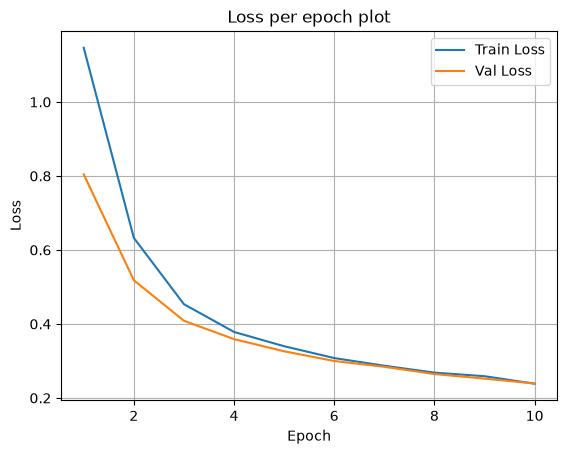

Saved best model (and EMA) at epoch 10 with val_loss 0.2392


Sampling: 100%|██████████| 25/25 [00:04<00:00,  5.29step/s]


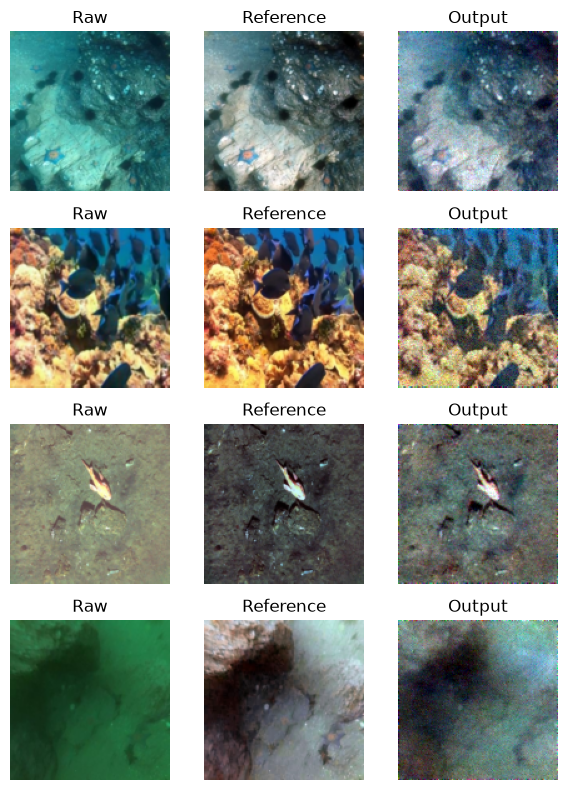

Epoch 11/150: 100%|██████████| 258/258 [05:28<00:00,  1.28s/batch]



==> Epoch 11 | Train loss: 0.2382 | Train PSNR: 24.03 dB
==> Epoch 11 | Val loss: 0.2360 | Val PSNR: 24.03 dB
Saved best model (and EMA) at epoch 11 with val_loss 0.2360


Epoch 12/150: 100%|██████████| 258/258 [05:28<00:00,  1.27s/batch]



==> Epoch 12 | Train loss: 0.2215 | Train PSNR: 24.14 dB
==> Epoch 12 | Val loss: 0.2280 | Val PSNR: 24.10 dB
Saved best model (and EMA) at epoch 12 with val_loss 0.2280


Epoch 13/150: 100%|██████████| 258/258 [05:31<00:00,  1.29s/batch]


...


==> Epoch 18 | Train loss: 0.1861 | Train PSNR: 25.28 dB
==> Epoch 18 | Val loss: 0.1997 | Val PSNR: 24.87 dB


Epoch 19/150: 100%|██████████| 258/258 [05:32<00:00,  1.29s/batch]



==> Epoch 19 | Train loss: 0.1853 | Train PSNR: 25.46 dB
==> Epoch 19 | Val loss: 0.1795 | Val PSNR: 25.20 dB
Saved best model (and EMA) at epoch 19 with val_loss 0.1795


Epoch 20/150: 100%|██████████| 258/258 [05:34<00:00,  1.30s/batch]



==> Epoch 20 | Train loss: 0.1801 | Train PSNR: 25.53 dB
==> Epoch 20 | Val loss: 0.1852 | Val PSNR: 25.46 dB


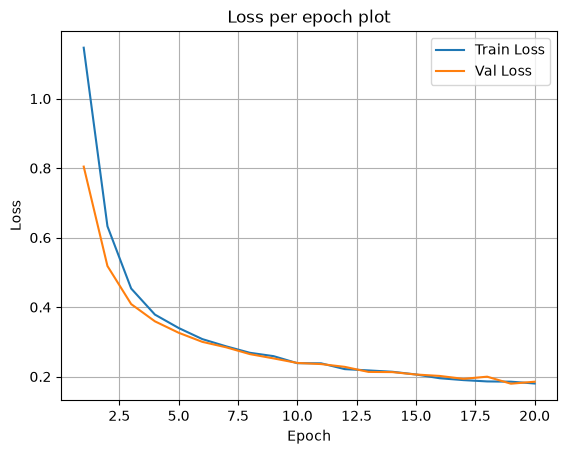

Sampling: 100%|██████████| 25/25 [00:05<00:00,  4.96step/s]


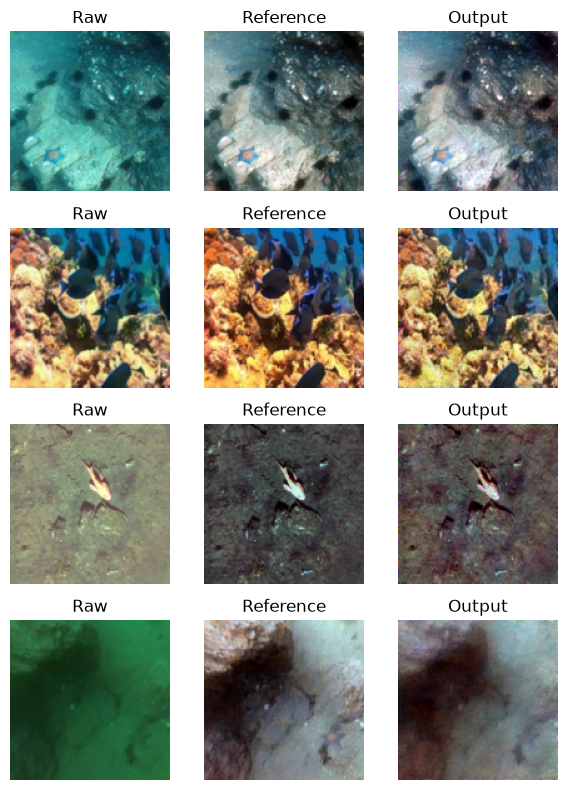

Epoch 21/150: 100%|██████████| 258/258 [05:44<00:00,  1.34s/batch]



==> Epoch 21 | Train loss: 0.1763 | Train PSNR: 25.79 dB
==> Epoch 21 | Val loss: 0.1844 | Val PSNR: 25.07 dB


Epoch 22/150: 100%|██████████| 258/258 [06:01<00:00,  1.40s/batch]



==> Epoch 22 | Train loss: 0.1712 | Train PSNR: 25.73 dB
==> Epoch 22 | Val loss: 0.1789 | Val PSNR: 24.90 dB
Saved best model (and EMA) at epoch 22 with val_loss 0.1789


Epoch 23/150: 100%|██████████| 258/258 [06:19<00:00,  1.47s/batch]


...


==> Epoch 28 | Train loss: 0.1525 | Train PSNR: 26.50 dB
==> Epoch 28 | Val loss: 0.1734 | Val PSNR: 26.28 dB


Epoch 29/150: 100%|██████████| 258/258 [06:11<00:00,  1.44s/batch]



==> Epoch 29 | Train loss: 0.1503 | Train PSNR: 26.48 dB
==> Epoch 29 | Val loss: 0.1558 | Val PSNR: 25.79 dB
Saved best model (and EMA) at epoch 29 with val_loss 0.1558


Epoch 30/150: 100%|██████████| 258/258 [06:12<00:00,  1.44s/batch]



==> Epoch 30 | Train loss: 0.1461 | Train PSNR: 26.68 dB
==> Epoch 30 | Val loss: 0.1650 | Val PSNR: 26.15 dB


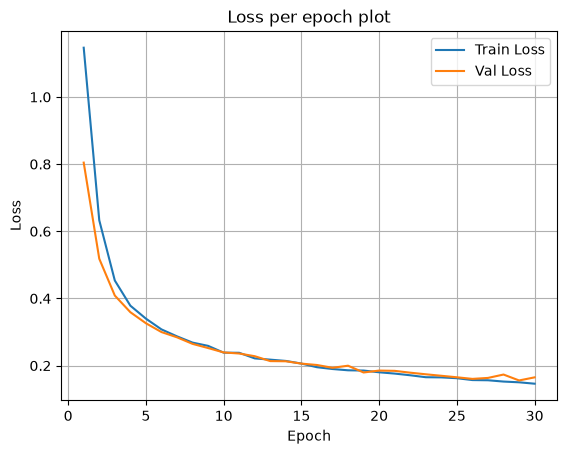

Sampling: 100%|██████████| 25/25 [00:05<00:00,  4.71step/s]


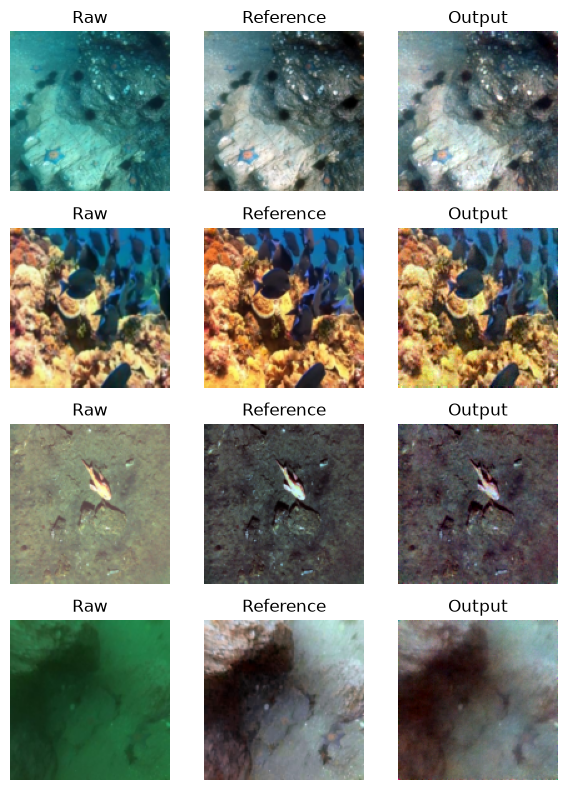

Epoch 31/150: 100%|██████████| 258/258 [06:10<00:00,  1.44s/batch]



==> Epoch 31 | Train loss: 0.1454 | Train PSNR: 26.82 dB
==> Epoch 31 | Val loss: 0.1514 | Val PSNR: 25.83 dB
Saved best model (and EMA) at epoch 31 with val_loss 0.1514


Epoch 32/150: 100%|██████████| 258/258 [06:12<00:00,  1.45s/batch]



==> Epoch 32 | Train loss: 0.1465 | Train PSNR: 26.83 dB
==> Epoch 32 | Val loss: 0.1583 | Val PSNR: 26.08 dB


Epoch 33/150: 100%|██████████| 258/258 [06:10<00:00,  1.43s/batch]


...


==> Epoch 38 | Train loss: 0.1367 | Train PSNR: 27.40 dB
==> Epoch 38 | Val loss: 0.1351 | Val PSNR: 26.74 dB
Saved best model (and EMA) at epoch 38 with val_loss 0.1351


Epoch 39/150: 100%|██████████| 258/258 [06:06<00:00,  1.42s/batch]



==> Epoch 39 | Train loss: 0.1325 | Train PSNR: 27.33 dB
==> Epoch 39 | Val loss: 0.1491 | Val PSNR: 27.26 dB


Epoch 40/150: 100%|██████████| 258/258 [06:06<00:00,  1.42s/batch]



==> Epoch 40 | Train loss: 0.1339 | Train PSNR: 27.35 dB
==> Epoch 40 | Val loss: 0.1360 | Val PSNR: 26.77 dB


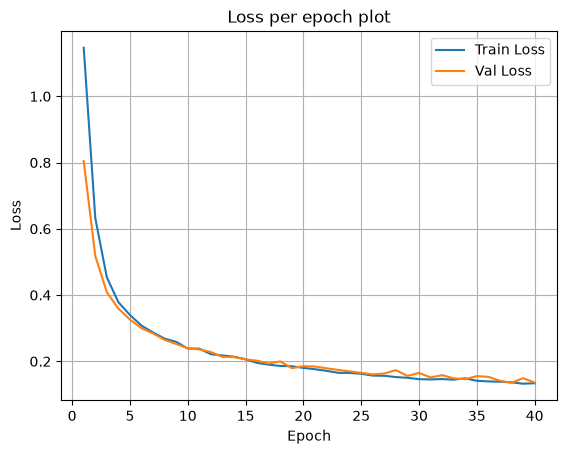

Sampling: 100%|██████████| 25/25 [00:04<00:00,  5.27step/s]


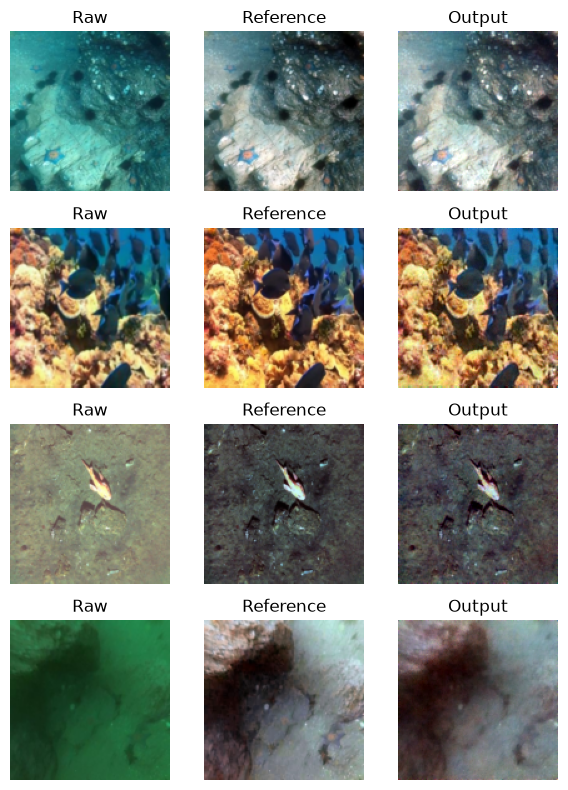

Epoch 41/150: 100%|██████████| 258/258 [05:56<00:00,  1.38s/batch]



==> Epoch 41 | Train loss: 0.1300 | Train PSNR: 27.43 dB
==> Epoch 41 | Val loss: 0.1380 | Val PSNR: 26.40 dB


Epoch 42/150: 100%|██████████| 258/258 [05:57<00:00,  1.38s/batch]



==> Epoch 42 | Train loss: 0.1302 | Train PSNR: 27.47 dB
==> Epoch 42 | Val loss: 0.1289 | Val PSNR: 27.07 dB
Saved best model (and EMA) at epoch 42 with val_loss 0.1289


Epoch 43/150: 100%|██████████| 258/258 [05:57<00:00,  1.38s/batch]


...


==> Epoch 48 | Train loss: 0.1191 | Train PSNR: 28.16 dB
==> Epoch 48 | Val loss: 0.1376 | Val PSNR: 27.32 dB


Epoch 49/150: 100%|██████████| 258/258 [05:55<00:00,  1.38s/batch]



==> Epoch 49 | Train loss: 0.1188 | Train PSNR: 28.03 dB
==> Epoch 49 | Val loss: 0.1340 | Val PSNR: 27.64 dB


Epoch 50/150: 100%|██████████| 258/258 [05:55<00:00,  1.38s/batch]



==> Epoch 50 | Train loss: 0.1233 | Train PSNR: 28.06 dB
==> Epoch 50 | Val loss: 0.1286 | Val PSNR: 27.45 dB


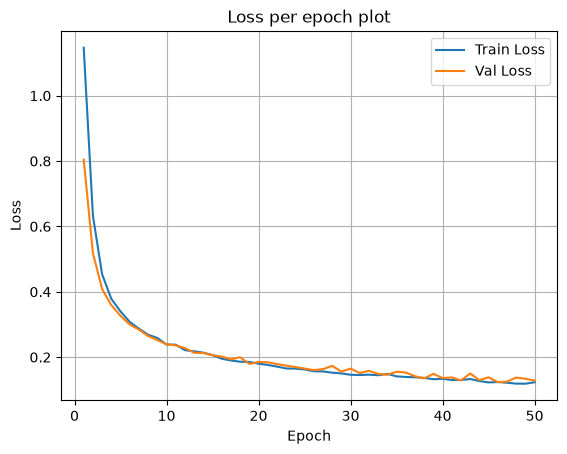

Sampling: 100%|██████████| 25/25 [00:04<00:00,  5.35step/s]


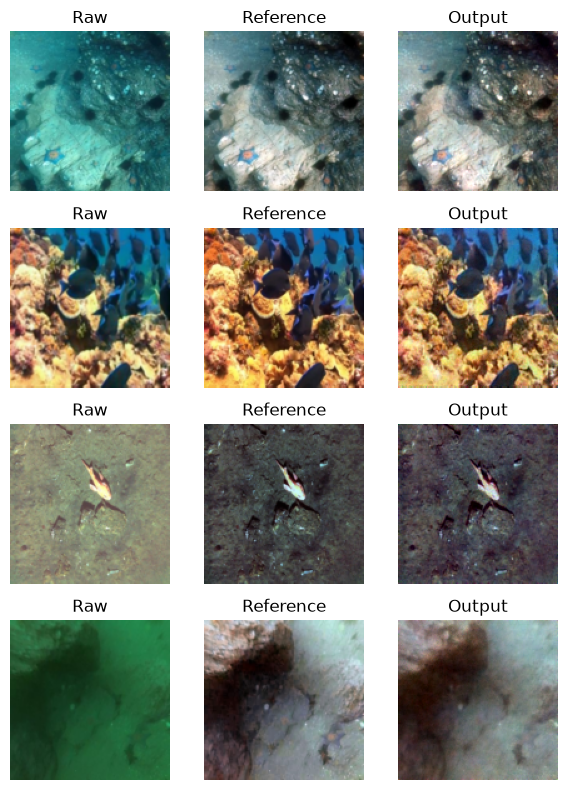

Epoch 51/150: 100%|██████████| 258/258 [06:08<00:00,  1.43s/batch]



==> Epoch 51 | Train loss: 0.1169 | Train PSNR: 28.05 dB
==> Epoch 51 | Val loss: 0.1423 | Val PSNR: 27.15 dB


Epoch 52/150: 100%|██████████| 258/258 [06:08<00:00,  1.43s/batch]



==> Epoch 52 | Train loss: 0.1208 | Train PSNR: 28.17 dB
==> Epoch 52 | Val loss: 0.1210 | Val PSNR: 27.54 dB
Saved best model (and EMA) at epoch 52 with val_loss 0.1210


Epoch 53/150: 100%|██████████| 258/258 [06:09<00:00,  1.43s/batch]


...


==> Epoch 58 | Train loss: 0.1161 | Train PSNR: 28.53 dB
==> Epoch 58 | Val loss: 0.1189 | Val PSNR: 27.32 dB


Epoch 59/150: 100%|██████████| 258/258 [06:08<00:00,  1.43s/batch]



==> Epoch 59 | Train loss: 0.1123 | Train PSNR: 28.50 dB
==> Epoch 59 | Val loss: 0.1159 | Val PSNR: 27.55 dB


Epoch 60/150: 100%|██████████| 258/258 [06:08<00:00,  1.43s/batch]



==> Epoch 60 | Train loss: 0.1150 | Train PSNR: 28.52 dB
==> Epoch 60 | Val loss: 0.1140 | Val PSNR: 26.95 dB


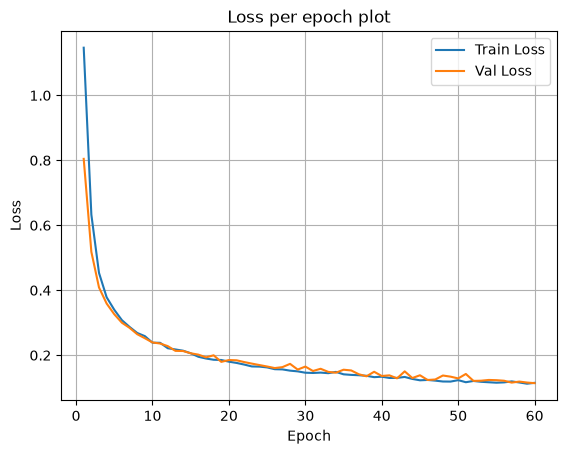

Saved best model (and EMA) at epoch 60 with val_loss 0.1140


Sampling: 100%|██████████| 25/25 [00:04<00:00,  5.26step/s]


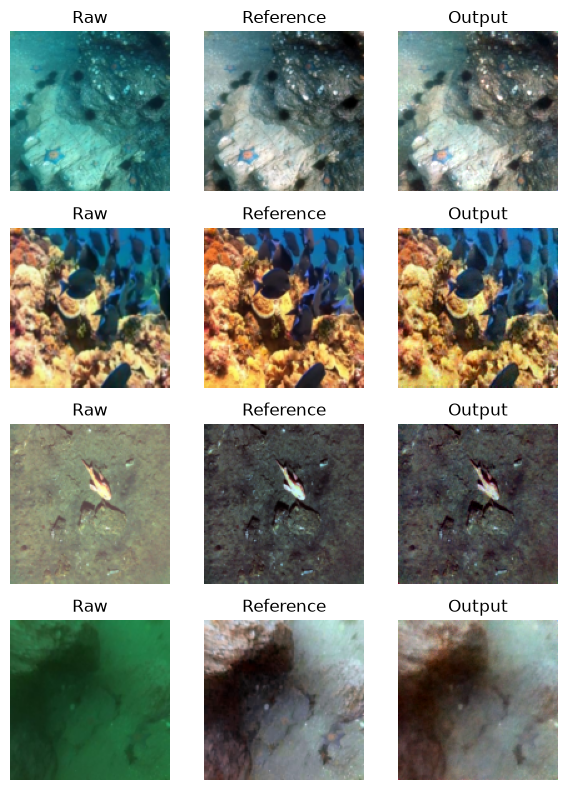

Epoch 61/150: 100%|██████████| 258/258 [06:14<00:00,  1.45s/batch]



==> Epoch 61 | Train loss: 0.1085 | Train PSNR: 28.47 dB
==> Epoch 61 | Val loss: 0.1239 | Val PSNR: 27.74 dB


Epoch 62/150: 100%|██████████| 258/258 [06:14<00:00,  1.45s/batch]



==> Epoch 62 | Train loss: 0.1118 | Train PSNR: 28.64 dB
==> Epoch 62 | Val loss: 0.1190 | Val PSNR: 27.64 dB


Epoch 63/150: 100%|██████████| 258/258 [06:14<00:00,  1.45s/batch]


...


==> Epoch 68 | Train loss: 0.1103 | Train PSNR: 28.85 dB
==> Epoch 68 | Val loss: 0.1152 | Val PSNR: 27.61 dB


Epoch 69/150: 100%|██████████| 258/258 [06:13<00:00,  1.45s/batch]



==> Epoch 69 | Train loss: 0.1069 | Train PSNR: 28.96 dB
==> Epoch 69 | Val loss: 0.1166 | Val PSNR: 27.96 dB


Epoch 70/150: 100%|██████████| 258/258 [06:13<00:00,  1.45s/batch]



==> Epoch 70 | Train loss: 0.1072 | Train PSNR: 28.86 dB
==> Epoch 70 | Val loss: 0.1213 | Val PSNR: 27.38 dB


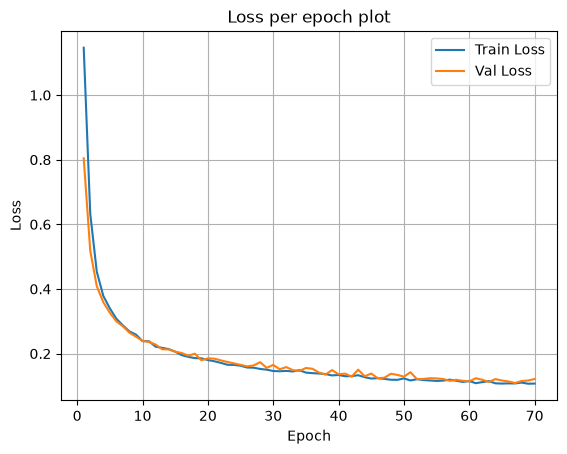

Sampling: 100%|██████████| 25/25 [00:04<00:00,  5.29step/s]


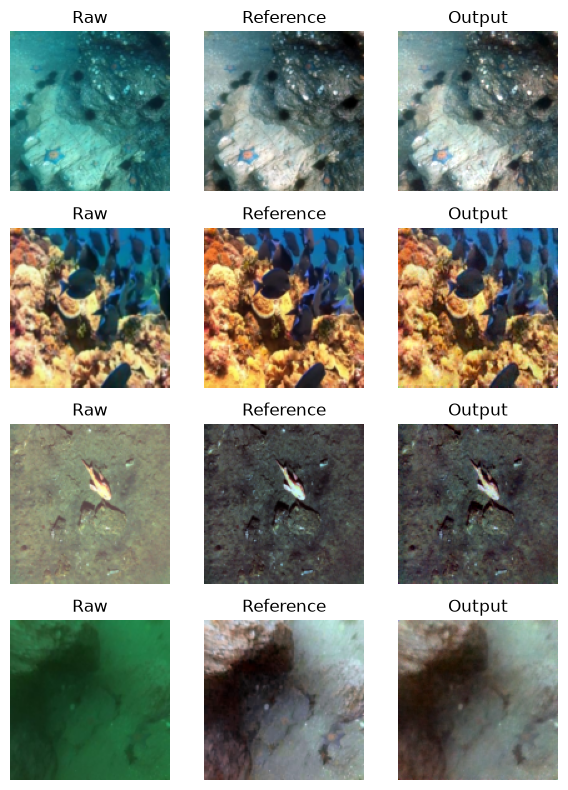

Epoch 71/150: 100%|██████████| 258/258 [06:07<00:00,  1.42s/batch]



==> Epoch 71 | Train loss: 0.1089 | Train PSNR: 28.94 dB
==> Epoch 71 | Val loss: 0.1159 | Val PSNR: 28.08 dB


Epoch 72/150: 100%|██████████| 258/258 [06:07<00:00,  1.43s/batch]



==> Epoch 72 | Train loss: 0.1089 | Train PSNR: 29.14 dB
==> Epoch 72 | Val loss: 0.1254 | Val PSNR: 27.52 dB


Epoch 73/150: 100%|██████████| 258/258 [06:07<00:00,  1.42s/batch]


...


==> Epoch 78 | Train loss: 0.1010 | Train PSNR: 29.27 dB
==> Epoch 78 | Val loss: 0.1222 | Val PSNR: 27.33 dB


Epoch 79/150: 100%|██████████| 258/258 [06:07<00:00,  1.43s/batch]



==> Epoch 79 | Train loss: 0.1045 | Train PSNR: 29.31 dB
==> Epoch 79 | Val loss: 0.1135 | Val PSNR: 27.81 dB


Epoch 80/150: 100%|██████████| 258/258 [06:07<00:00,  1.42s/batch]



==> Epoch 80 | Train loss: 0.1035 | Train PSNR: 29.32 dB
==> Epoch 80 | Val loss: 0.1138 | Val PSNR: 28.42 dB


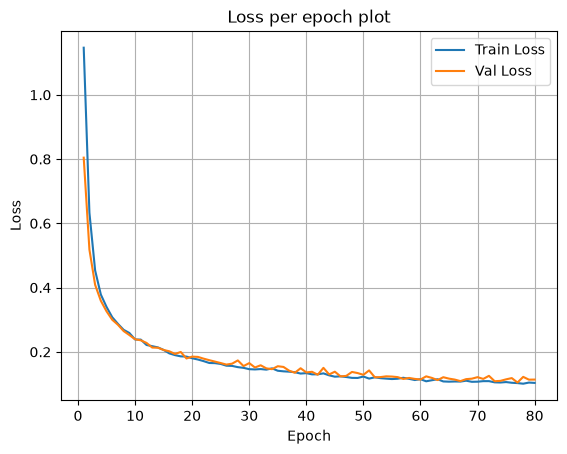

Sampling: 100%|██████████| 25/25 [00:04<00:00,  5.13step/s]


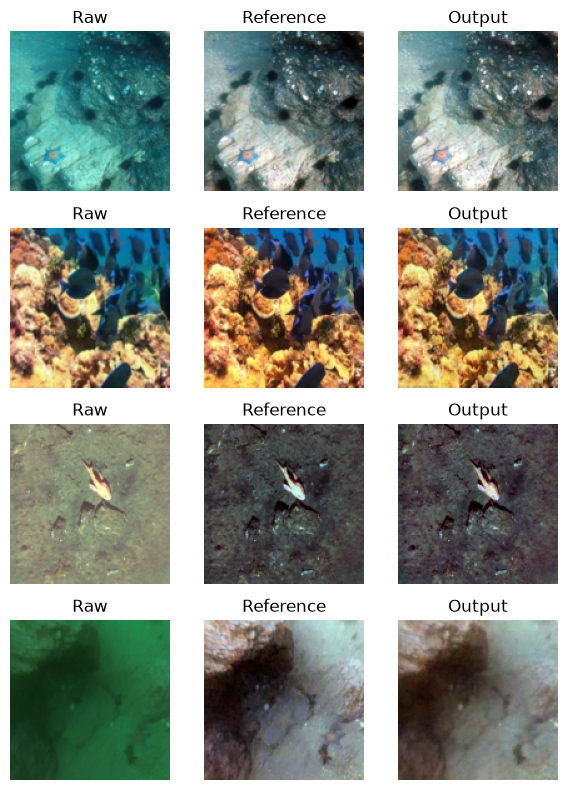

Epoch 81/150: 100%|██████████| 258/258 [06:40<00:00,  1.55s/batch]



==> Epoch 81 | Train loss: 0.1076 | Train PSNR: 29.38 dB
==> Epoch 81 | Val loss: 0.1065 | Val PSNR: 27.23 dB


Epoch 82/150: 100%|██████████| 258/258 [06:40<00:00,  1.55s/batch]



==> Epoch 82 | Train loss: 0.1019 | Train PSNR: 29.44 dB
==> Epoch 82 | Val loss: 0.1046 | Val PSNR: 28.22 dB
Saved best model (and EMA) at epoch 82 with val_loss 0.1046


Epoch 83/150: 100%|██████████| 258/258 [06:39<00:00,  1.55s/batch]


...


==> Epoch 88 | Train loss: 0.0981 | Train PSNR: 29.43 dB
==> Epoch 88 | Val loss: 0.1050 | Val PSNR: 27.75 dB


Epoch 89/150: 100%|██████████| 258/258 [06:39<00:00,  1.55s/batch]



==> Epoch 89 | Train loss: 0.0994 | Train PSNR: 29.68 dB
==> Epoch 89 | Val loss: 0.1020 | Val PSNR: 27.71 dB
Saved best model (and EMA) at epoch 89 with val_loss 0.1020


Epoch 90/150: 100%|██████████| 258/258 [06:39<00:00,  1.55s/batch]



==> Epoch 90 | Train loss: 0.0960 | Train PSNR: 29.53 dB
==> Epoch 90 | Val loss: 0.1170 | Val PSNR: 28.29 dB


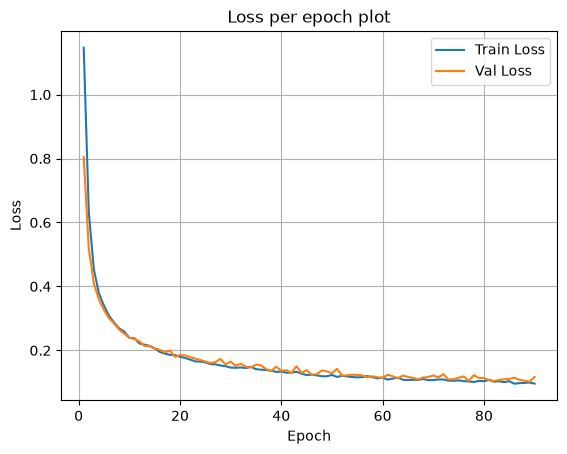

Sampling: 100%|██████████| 25/25 [00:04<00:00,  5.39step/s]


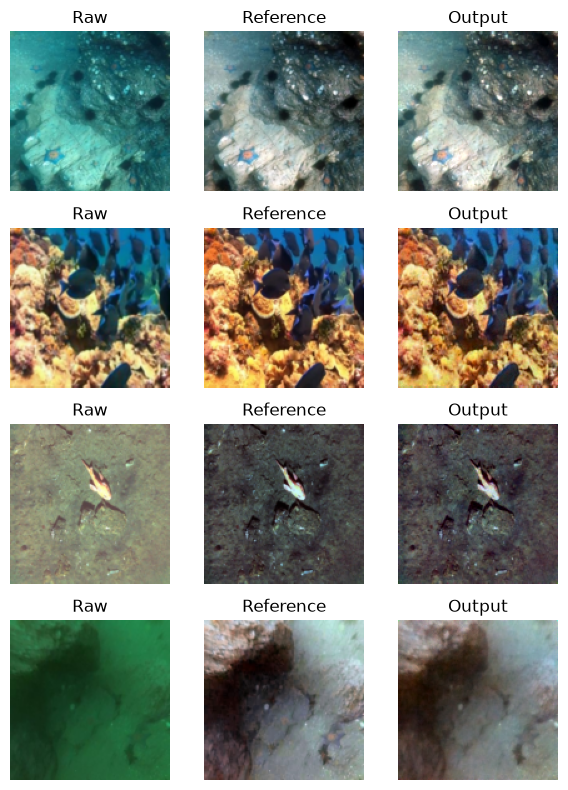

Epoch 91/150: 100%|██████████| 258/258 [06:16<00:00,  1.46s/batch]



==> Epoch 91 | Train loss: 0.0944 | Train PSNR: 29.59 dB
==> Epoch 91 | Val loss: 0.1128 | Val PSNR: 27.77 dB


Epoch 92/150: 100%|██████████| 258/258 [06:17<00:00,  1.46s/batch]



==> Epoch 92 | Train loss: 0.1026 | Train PSNR: 29.69 dB
==> Epoch 92 | Val loss: 0.1160 | Val PSNR: 28.07 dB


Epoch 93/150: 100%|██████████| 258/258 [06:16<00:00,  1.46s/batch]


...


==> Epoch 98 | Train loss: 0.0984 | Train PSNR: 29.69 dB
==> Epoch 98 | Val loss: 0.1094 | Val PSNR: 28.77 dB


Epoch 99/150: 100%|██████████| 258/258 [06:15<00:00,  1.46s/batch]



==> Epoch 99 | Train loss: 0.0978 | Train PSNR: 29.78 dB
==> Epoch 99 | Val loss: 0.1009 | Val PSNR: 28.02 dB


Epoch 100/150: 100%|██████████| 258/258 [06:16<00:00,  1.46s/batch]



==> Epoch 100 | Train loss: 0.0966 | Train PSNR: 29.75 dB
==> Epoch 100 | Val loss: 0.1140 | Val PSNR: 28.44 dB


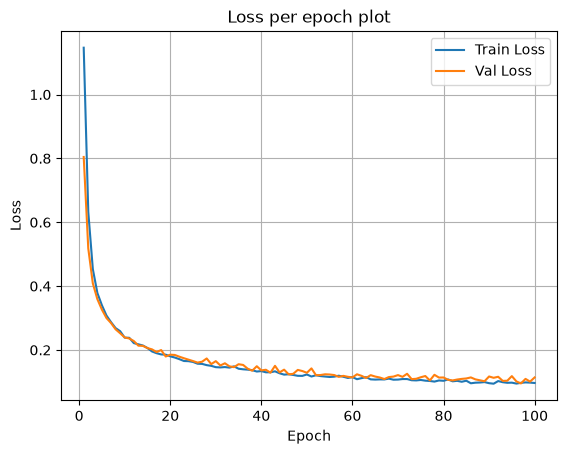

Sampling: 100%|██████████| 25/25 [00:04<00:00,  5.34step/s]


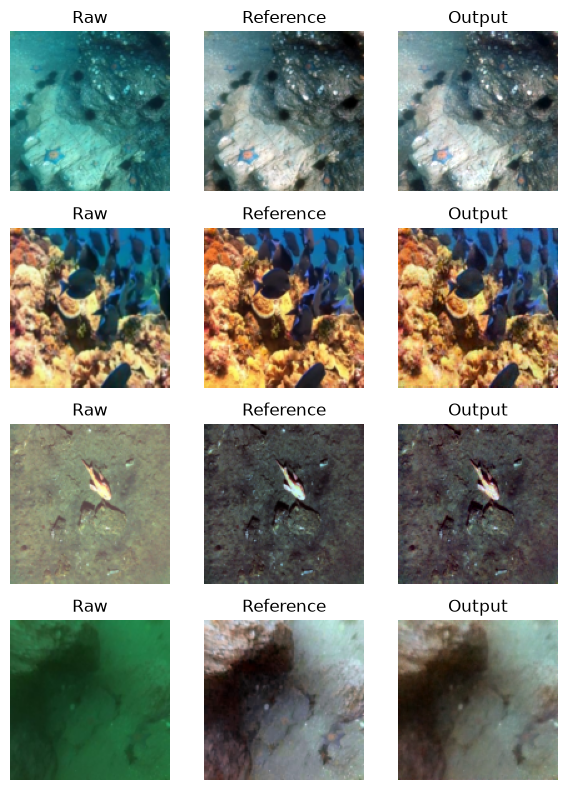

Epoch 101/150: 100%|██████████| 258/258 [06:01<00:00,  1.40s/batch]



==> Epoch 101 | Train loss: 0.1006 | Train PSNR: 29.91 dB
==> Epoch 101 | Val loss: 0.1026 | Val PSNR: 28.32 dB


Epoch 102/150: 100%|██████████| 258/258 [05:58<00:00,  1.39s/batch]



==> Epoch 102 | Train loss: 0.0971 | Train PSNR: 29.95 dB
==> Epoch 102 | Val loss: 0.1005 | Val PSNR: 28.48 dB


Epoch 103/150: 100%|██████████| 258/258 [05:59<00:00,  1.39s/batch]


...


==> Epoch 108 | Train loss: 0.0964 | Train PSNR: 30.02 dB
==> Epoch 108 | Val loss: 0.1021 | Val PSNR: 27.75 dB


Epoch 109/150: 100%|██████████| 258/258 [05:57<00:00,  1.39s/batch]



==> Epoch 109 | Train loss: 0.0925 | Train PSNR: 29.94 dB
==> Epoch 109 | Val loss: 0.0976 | Val PSNR: 28.55 dB


Epoch 110/150: 100%|██████████| 258/258 [05:57<00:00,  1.39s/batch]



==> Epoch 110 | Train loss: 0.0951 | Train PSNR: 29.92 dB
==> Epoch 110 | Val loss: 0.1098 | Val PSNR: 28.94 dB


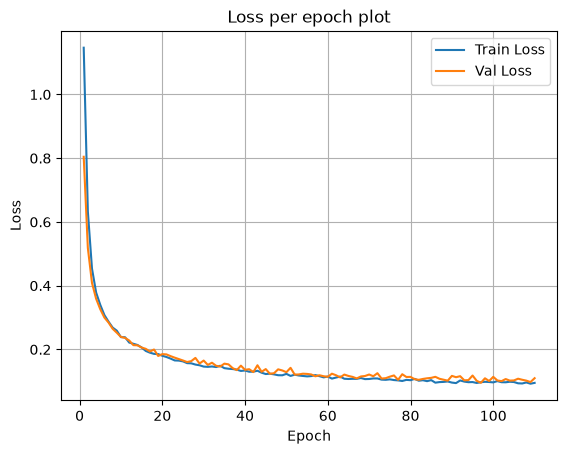

Sampling: 100%|██████████| 25/25 [00:04<00:00,  5.40step/s]


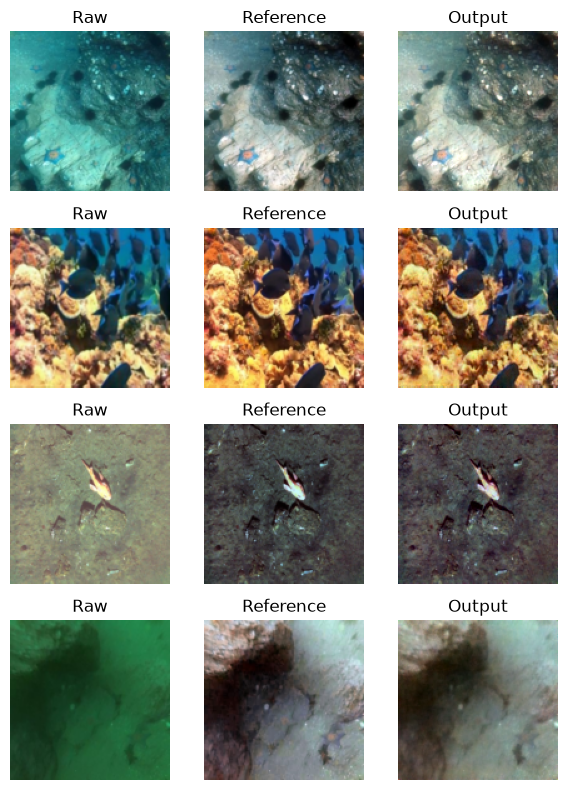

Epoch 111/150: 100%|██████████| 258/258 [06:06<00:00,  1.42s/batch]



==> Epoch 111 | Train loss: 0.0957 | Train PSNR: 29.99 dB
==> Epoch 111 | Val loss: 0.1075 | Val PSNR: 27.79 dB


Epoch 112/150: 100%|██████████| 258/258 [06:04<00:00,  1.41s/batch]



==> Epoch 112 | Train loss: 0.0940 | Train PSNR: 30.12 dB
==> Epoch 112 | Val loss: 0.1153 | Val PSNR: 28.42 dB


Epoch 113/150: 100%|██████████| 258/258 [06:04<00:00,  1.41s/batch]


...


==> Epoch 118 | Train loss: 0.0956 | Train PSNR: 30.19 dB
==> Epoch 118 | Val loss: 0.1046 | Val PSNR: 28.41 dB


Epoch 119/150: 100%|██████████| 258/258 [06:04<00:00,  1.41s/batch]



==> Epoch 119 | Train loss: 0.0918 | Train PSNR: 30.09 dB
==> Epoch 119 | Val loss: 0.1010 | Val PSNR: 28.38 dB


Epoch 120/150: 100%|██████████| 258/258 [06:15<00:00,  1.46s/batch]



==> Epoch 120 | Train loss: 0.0952 | Train PSNR: 30.10 dB
==> Epoch 120 | Val loss: 0.0991 | Val PSNR: 28.43 dB


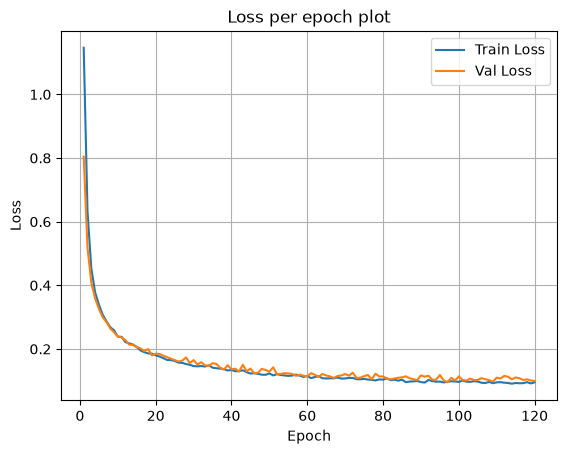

Sampling: 100%|██████████| 25/25 [00:04<00:00,  5.49step/s]


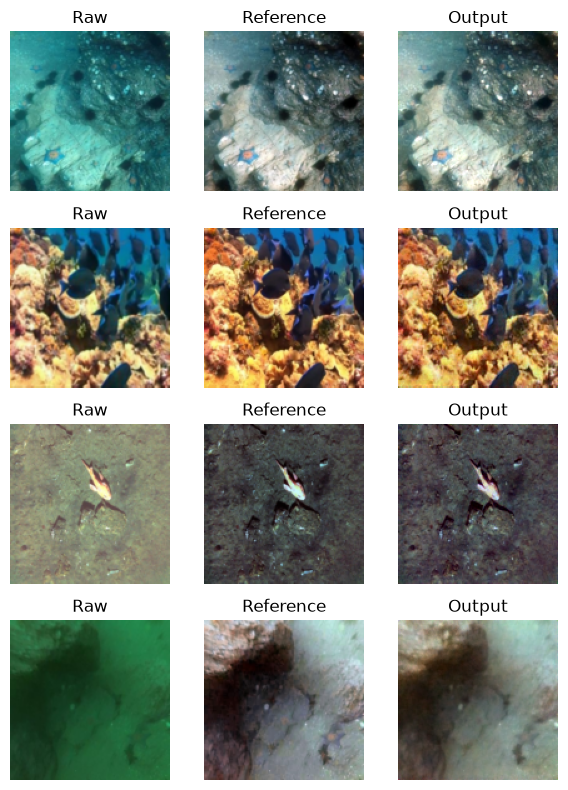

Epoch 121/150: 100%|██████████| 258/258 [06:14<00:00,  1.45s/batch]



==> Epoch 121 | Train loss: 0.0918 | Train PSNR: 30.14 dB
==> Epoch 121 | Val loss: 0.1034 | Val PSNR: 28.31 dB


Epoch 122/150: 100%|██████████| 258/258 [06:14<00:00,  1.45s/batch]



==> Epoch 122 | Train loss: 0.0947 | Train PSNR: 30.21 dB
==> Epoch 122 | Val loss: 0.1038 | Val PSNR: 28.37 dB


Epoch 123/150: 100%|██████████| 258/258 [06:17<00:00,  1.46s/batch]


...


==> Epoch 125 | Train loss: 0.0917 | Train PSNR: 30.22 dB
==> Epoch 125 | Val loss: 0.1144 | Val PSNR: 28.30 dB


Epoch 126/150: 100%|██████████| 258/258 [06:13<00:00,  1.45s/batch]



==> Epoch 126 | Train loss: 0.0891 | Train PSNR: 30.14 dB
==> Epoch 126 | Val loss: 0.0959 | Val PSNR: 28.31 dB


Epoch 127/150: 100%|██████████| 258/258 [06:22<00:00,  1.48s/batch]



==> Epoch 127 | Train loss: 0.0933 | Train PSNR: 30.16 dB
==> Epoch 127 | Val loss: 0.1013 | Val PSNR: 28.40 dB
No improvement for 30 epochs. Early stopping at epoch 127.
Training finished. Loss plots and records saved in ./Results_valid


In [7]:
per_step_train_loss, per_epoch_train_loss, per_epoch_val_loss, best_model_path = train_cond_ddpm(raw_dir, ref_dir,
                epochs=150, batch_size=16, lr=1e-5, image_size=128,
                sample_every=10, sample_steps=25)

In [9]:
# ============ Test & Metrics ============ #
import os
import torch
import torch.nn.functional as F
from torchvision.utils import save_image
from skimage.metrics import peak_signal_noise_ratio as compare_psnr
from skimage.metrics import structural_similarity as compare_ssim
import numpy as np
from PIL import Image
from scipy import ndimage
import lpips

# --- 设置 ---
device = "cuda" if torch.cuda.is_available() else "cpu"
model_path = "./model_plot/best_model_dinov2_ema.pth"
save_dir3 = "./Results_test"
save_dir4 = "./metrics"
os.makedirs(save_dir3, exist_ok=True)
os.makedirs(save_dir4, exist_ok=True)

# --- 初始化模型 ---
model = CondUNetCA(c_in=7, c_out=3, base=64, cond_dim=128).to(device)
model.load_state_dict(torch.load(model_path, map_location=device))
model.eval()

# --- Feature Extractors ---
vit  = FeatureExtractor("vit_base_patch16_224", img_size=image_size, out_dim=128).to(device)
swin = FeatureExtractor("dinov2_vitb14", img_size=image_size, out_dim=128).to(device)
for p in vit.parameters(): p.requires_grad = False
for p in swin.parameters(): p.requires_grad = False
lpips_vgg = lpips.LPIPS(net='vgg').to(device)

# --- 测试 ---
all_psnr = []
all_ssim = []
all_uiqm = []   # 需要实现或用第三方库
all_uciqe = []  # 需要实现或用第三方库
all_lpips = []

def _uicm(img):
    R = img[:,:,0]
    G = img[:,:,1]
    B = img[:,:,2]
    rg = R - G
    yb = 0.5*(R+G) - B
    mu_rg, mu_yb = np.mean(rg), np.mean(yb)
    sig_rg, sig_yb = np.std(rg), np.std(yb)
    return (-0.0268 * np.sqrt(mu_rg**2 + mu_yb**2)) + (0.1586 * np.sqrt(sig_rg**2 + sig_yb**2))

def _uism(img):
    gray = cv2.cvtColor((img*255).astype(np.uint8), cv2.COLOR_RGB2GRAY)
    sobel = ndimage.sobel(gray.astype(float))
    return np.mean(np.abs(sobel)) / 255.0

def _uiconm(img):
    gray = cv2.cvtColor((img*255).astype(np.uint8), cv2.COLOR_RGB2GRAY)
    return np.std(gray) / 255.0

def compute_uiqm(img):
    """
    UIQM: Underwater Image Quality Measure
    img: numpy array in [0,1], shape (H,W,3)
    """
    return 0.0282*_uicm(img) + 0.2953*_uism(img) + 3.5753*_uiconm(img)

def compute_uciqe(img):
    """
    UCIQE: Underwater Color Image Quality Evaluation
    img: numpy array in [0,1], shape (H,W,3)
    """
    lab = cv2.cvtColor((img*255).astype(np.uint8), cv2.COLOR_RGB2LAB)
    L, A, B = cv2.split(lab)
    L = L.astype(np.float32) / 255.0

    chroma = np.sqrt((A-128)**2 + (B-128)**2)
    chroma = chroma / 360.624

    # coefficients from original paper
    c1, c2, c3 = 0.4680, 0.2745, 0.2576
    uc = np.std(chroma)
    con_l = np.percentile(L, 99) - np.percentile(L, 1)
    mu_s = np.mean(chroma)

    con_l = max(con_l, 1e-6)

    return c1*uc + c2*con_l + c3*mu_s

with torch.no_grad():
    for idx, (raw, ref) in enumerate(dl_test):
        raw, ref = raw.to(device), ref.to(device)
        B, C, H, W = raw.shape
        B, C, H, W = ref.shape

        pred, _ = sample_enhanced(model, diffusion, raw, vit, swin, num_steps=25, use_dynamic_thres=True)
        # pred = pred[0]
        # 转换到 [0,1] 用于保存和计算指标
        pred01 = ((pred + 1) / 2.0).cpu().clamp(0,1)
        ref01  = ((ref + 1) / 2.0).cpu().clamp(0,1)

        pred_lpips = pred01 * 2 - 1
        ref_lpips = ref01 * 2 - 1

        for b in range(B):
            # 保存图片
            save_image(pred01[b], os.path.join(save_dir3, f"test_{idx*B + b:03d}.png"))

            # 转为 numpy
            pred_np = pred01[b].permute(1,2,0).numpy()
            ref_np  = ref01[b].permute(1,2,0).numpy()
            pred_uint8 = (pred_np * 255).astype(np.uint8)

            # PSNR / SSIM
            psnr_val = compare_psnr(ref_np, pred_np, data_range=1.0)
            ssim_val = compare_ssim(ref_np, pred_np, channel_axis=2, data_range=1.0)
            all_psnr.append(psnr_val)
            all_ssim.append(ssim_val)

            # UIQM / UCIQE 可用第三方库函数
            uiqm_val = compute_uiqm(pred_uint8)
            uciqe_val = compute_uciqe(pred_uint8)
            all_uiqm.append(uiqm_val)
            all_uciqe.append(uciqe_val)

            # LPIPS
            lpips_val = lpips_vgg(pred_lpips[b:b+1].to(device), ref_lpips[b:b+1].to(device))
            all_lpips.append(lpips_val.item())

# --- 输出指标平均值 ---
print(f"Average PSNR: {np.mean(all_psnr):.2f}")
print(f"Average SSIM: {np.mean(all_ssim):.4f}")
print(f"Average UIQM: {np.mean(all_uiqm):.4f}")
print(f"Average UCIQE: {np.mean(all_uciqe):.4f}")
print(f"Average LPIPS: {np.mean(all_lpips):.4f}")
print(f"All test images saved to {save_dir3}")

# --- Save results to txt ---
results_file = os.path.join(save_dir4, "results.txt")
with open(results_file, "w") as f:
    f.write(f"Average PSNR:  {np.mean(all_psnr):.2f}\n")
    f.write(f"Average SSIM:  {np.mean(all_ssim):.4f}\n")
    f.write(f"Average UIQM:  {np.mean(all_uiqm):.4f}\n")
    f.write(f"Average UCIQE: {np.mean(all_uciqe):.4f}\n")
    f.write(f"Average LPIPS: {np.mean(all_lpips):.4f}\n")

C:\Users\PC\AppData\Local\Temp\ipykernel_29344\3076867622.py:23: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(model_path, map_location=devi

Setting up [LPIPS] perceptual loss: trunk [vgg], v[0.1], spatial [off]
Loading model from: C:\Users\PC\anaconda3\envs\dissertation\Lib\site-packages\lpips\weights\v0.1\vgg.pth


Sampling: 100%|██████████| 25/25 [00:01<00:00, 14.42step/s]


Average PSNR: 20.51
Average SSIM: 0.8602
Average UIQM: 0.9334
Average UCIQE: 0.1972
Average LPIPS: 0.1943
All test images saved to ./Results_test


In [ ]:
import torch
import matplotlib.pyplot as plt

# Load the loss dictionary
losses = torch.load("./model_plot/loss_records.pth")  # 改成你的路径
per_epoch_train_loss = losses["per_epoch_train_loss"]
per_epoch_val_loss   = losses["per_epoch_val_loss"]

# Plot
plt.figure(figsize=(10,5))
plt.plot(range(1, len(per_epoch_train_loss)+1), per_epoch_train_loss, label="Train Loss")
plt.plot(range(1, len(per_epoch_val_loss)+1), per_epoch_val_loss, label="Val Loss")
plt.title("Per Epoch Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
save_dir5 = "./Results_valid"
os.makedirs(save_dir5, exist_ok=True)

per_step_train_loss = losses["per_step_train_loss"]
plt.figure(figsize=(10,5))
plt.plot(per_step_train_loss, label="Train Loss per Step")
plt.xlabel("Step")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.savefig(os.path.join(save_dir5, "loss_per_step.png"))
plt.show()

In [ ]:
import torch
import pandas as pd
import numpy as np

losses = torch.load("./model_plot/loss_records.pth")
per_step_train_loss  = losses["per_step_train_loss"]
per_epoch_train_loss = losses["per_epoch_train_loss"]
per_epoch_val_loss   = losses["per_epoch_val_loss"]

# 找到最长长度
max_len = max(len(per_step_train_loss), len(per_epoch_train_loss), len(per_epoch_val_loss))

# 用 NaN 填充短的列
per_step_train_loss  = per_step_train_loss + [np.nan]*(max_len - len(per_step_train_loss))
per_epoch_train_loss = per_epoch_train_loss + [np.nan]*(max_len - len(per_epoch_train_loss))
per_epoch_val_loss   = per_epoch_val_loss + [np.nan]*(max_len - len(per_epoch_val_loss))

df = pd.DataFrame({
    "step_train_loss": per_step_train_loss,
    "epoch_train_loss": per_epoch_train_loss,
    "epoch_val_loss": per_epoch_val_loss
})

df.to_csv("./loss_records.csv", index=False)
print("Losses saved to ./UIEB-Test/loss_records.csv")
print(df.head(20))


In [ ]:
# 必要库
from ipywidgets import HBox, IntSlider, Output, Layout
import matplotlib.pyplot as plt
from IPython.display import display, clear_output

device = "cuda" if torch.cuda.is_available() else "cpu"
image_size = 128
sample_steps = 1000

# 1. 加载 best model
model = CondUNetCA(c_in=7, c_out=3, base=64, cond_dim=128).to(device)
model.load_state_dict(torch.load("./model_plot/best_model.pth"))
model.eval()

# 2. Feature Extractors
vit  = FeatureExtractor("vit_base_patch16_224", img_size=image_size, out_dim=128).to(device)
swin = FeatureExtractor("swin_base_patch4_window7_224", img_size=image_size, out_dim=128).to(device)
for p in vit.parameters(): p.requires_grad = False
for p in swin.parameters(): p.requires_grad = False

# 3. 准备可视化的输入 (这里用 test 集前 2 张)
raw_vis, ref_vis = next(iter(dl_test))
raw_vis, ref_vis = raw_vis[:5].to(device), ref_vis[:5].to(device)

final_img, x_t_all = sample_enhanced(model, diffusion, raw_vis, vit, swin, num_steps=sample_steps)
x_t_all_cpu = [img.cpu() for img in x_t_all]

out = Output(layout=Layout(width='500px', height='500px'))

slider = IntSlider(
    value=0,
    min=0,
    max=len(x_t_all_cpu)-1,
    step=1,
    description='Step:',
    orientation='vertical',  # 垂直滑块
    layout=Layout(height='400px', width='50px')  # 固定滑块大小
)
slider.style.handle_width = '30px'
slider.style.description_width = '50px'

def on_slider_change(change):
    step_idx = change['new']
    with out:
        clear_output(wait=True)
        imgs = x_t_all_cpu[step_idx][:5]  # 前 5 张图
        fig = plt.figure(figsize=(6,3))

        # 大图
        ax_main = fig.add_axes([0.0, 0.0, 0.65, 1.0])  # [left, bottom, width, height]
        img_main = ((imgs[0] + 1) / 2).clamp(0,1).permute(1,2,0).numpy()
        ax_main.imshow(img_main)
        ax_main.axis('off')

        # 小图 2x2
        small_positions = [
            [0.57, 0.52, 0.30, 0.45],  # top-left
            [0.57, 0.02, 0.30, 0.45],  # bottom-left
            [0.82, 0.52, 0.30, 0.45],  # top-right
            [0.82, 0.02, 0.30, 0.45]   # bottom-right
        ]
        for i, pos in enumerate(small_positions):
            ax = fig.add_axes(pos)
            img_s = ((imgs[i+1] + 1) / 2).clamp(0,1).permute(1,2,0).numpy()
            ax.imshow(img_s)
            ax.axis('off')

        plt.show()
        print(f"step: {step_idx}")

slider.observe(on_slider_change, names='value')

# 水平布局：图像左，滑块右
display(HBox([out, slider]))

# 初始化显示
on_slider_change({'new': 0})